
# What is Machine Learning? 
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Danselem/brics_astro/blob/main/ml/week1/01_Supervised_Learning.ipynb)
## Supervised Learning I

**Course:** Machine Learning in Astronomy — Week 1 Pre-Work Notebook
**Audience:** MSc/PhD students in Astronomy, Space Science, Solar Physics, Cosmology

## Bridge from Notebook 0

In Notebook 0 you built the raw ingredients: gradients and gradient descent, vectors and covariance, probability distributions, Bayes' theorem, and maximum likelihood. This notebook is where those ingredients start doing real work. Concretely:

- The "loss surface" you descended in Notebook 0 §3 **is** the object a `scikit-learn` model minimizes internally when you call `.fit()`.
- The Gaussian-noise assumption behind MLE (Notebook 0 §7) is *why* mean squared error is the default loss for regression.
- The "more data → narrower posterior" idea from Notebook 0 §6 reappears here as "more data → more reliable model evaluation."

Nothing in this notebook requires re-deriving anything from scratch — it requires *recognizing* the same ideas wearing new clothes.

## A note on the data used here

Every code example in this notebook uses one real, open, publicly available dataset: **100,000 real astronomical objects from the Sloan Digital Sky Survey Data Release 17 (SDSS17)**, each with real photometric measurements and a real spectroscopically-confirmed class label (star, galaxy, or quasar) and a real measured redshift. This is not simulated data — it's actual sky survey output, and everything you compute on it reflects real astrophysical populations (including real messiness: real class imbalance, and even a couple of real bad/missing-value flags you'll learn to catch).

Even though the dataset itself comes from optical astronomy, the *concepts* in this notebook apply identically whether your own data is a light curve from a spacecraft, a magnetogram from a solar observatory, or an N-body simulation snapshot — the running examples and exercises throughout deliberately pull from solar physics, cosmology, and space science as well, so keep an eye out for how your own subfield maps onto each idea.

## Learning objectives

By the end of this notebook you should be able to:
- Explain, with examples from multiple subfields, the difference between supervised, unsupervised, and semi-supervised learning
- Explain the vocabulary of the supervised learning workflow: features, labels, hypothesis space, loss, train/validation/test splits
- Distinguish a regression problem from a classification problem, including cases that could reasonably be framed either way
- Explain why feature scaling matters and apply it correctly
- Build, evaluate, and interpret a linear regression model on real data
- Build, evaluate, and interpret both a binary and a multi-class classification model on real data
- Read a confusion matrix (both 2×2 and N×N), and choose appropriate metrics under class imbalance
- Explain why a single train/test split can mislead you, and use k-fold cross-validation instead
- Recognize overfitting and underfitting in a supervised learning context

## Table of contents
1. What is Machine Learning, really?
2. The supervised learning workflow
3. Regression vs. classification
4. Feature preprocessing
5. Regression, properly built out
6. Classification, properly built out (binary *and* multi-class)
7. Classification evaluation metrics, generalized
8. Cross-validation
9. Overfitting/underfitting, revisited
10. Self-check questions


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay, roc_auc_score
)

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready.")

Environment ready.



## 1. What is Machine Learning, really?

### Rule-based vs. learned systems
Suppose you want a program that separates stars from galaxies in a photometric catalog. One approach: sit down, think hard about the physics, and write explicit rules ("if the object is unresolved and its color is bluer than X, call it a star"). This can work, but real data is messy — overlapping populations, noise, edge cases — and rules like this become long, brittle lists of special cases that someone has to maintain by hand.

The machine learning approach flips this around: instead of *writing* the rule, you *show the computer examples* of correctly-labeled objects (stars here, galaxies there) and let an algorithm find a rule — a mathematical function — that separates them, by minimizing a loss function over those examples (exactly the process from Notebook 0 §3). The "rule" the computer finds might not be interpretable as a simple sentence, but it can be far more accurate and can be re-derived automatically as more data comes in.

### The three flavors of learning, with examples across your subfields

| Type | What you have | What you don't have | Example (spanning subfields) |
|---|---|---|---|
| **Supervised** | Input features **and** correct output labels | — | Predicting a galaxy's redshift from its photometry (labels: spectroscopically confirmed redshifts); predicting a solar flare's peak X-ray class from magnetogram features (labels: GOES-catalogued flare classes); classifying a light curve as "exoplanet transit" or "not" (labels: confirmed planets from follow-up observations) |
| **Unsupervised** | Input features only | Labels | Grouping stars in a Gaia color–magnitude diagram into natural populations with no predefined categories; finding structure in a set of unlabeled solar wind time series; discovering sub-populations in a catalog of galaxy cluster properties |
| **Semi-supervised** | A few labeled examples **and** lots of unlabeled data | Labels for most of the data | A handful of spectroscopically confirmed variable star types among millions of unclassified light curves from a survey like ZTF or LSST; a small set of confirmed coronal mass ejections (CMEs) among a much larger archive of unlabeled solar imagery |

Notice something important: the *type* of problem (supervised/unsupervised/semi-supervised) is about **what data you have**, not about your subfield. A cosmologist, a solar physicist, and a stellar astronomer can all face the exact same category of ML problem.

This week focuses entirely on **supervised** learning — Week 2 covers unsupervised and semi-supervised.

**🔧 Try it yourself (no code needed):** Before reading further, decide for each of these whether it's supervised, unsupervised, or semi-supervised, and jot down why:
1. Predicting a star's surface temperature from its spectrum, using a large archive of spectra with known temperatures from independent measurements.
2. Clustering a catalog of galaxy morphologies with no existing classification.
3. Classifying sunspot groups by magnetic complexity type, using a small set of expert-labeled groups and a huge unlabeled archive of daily magnetogram images.
4. Estimating the mass of a galaxy cluster from its X-ray temperature, using a sample of clusters with independently measured (dynamical) masses.

*(Answers: 1 — supervised; 2 — unsupervised; 3 — semi-supervised; 4 — supervised. If you got these right, you're ready to move on.)*



## 2. The Supervised Learning Workflow

Every supervised learning problem, regardless of subfield, uses the same vocabulary:

- **Features** ($x$): the measured inputs (e.g. photometric magnitudes, spectral line strengths, orbital parameters).
- **Labels** ($y$): the thing you're trying to predict (e.g. redshift, flare class, planet radius).
- **Model / hypothesis** ($h_\theta$): a function, controlled by adjustable parameters $\theta$, that maps features to a predicted label: $\hat{y} = h_\theta(x)$.
- **Loss function** ($J(\theta)$): a number measuring how wrong the model's predictions are — this is exactly the "loss surface" from Notebook 0 §2–3, and training means walking downhill on it.

### Why we never train and evaluate on the same data
If you tune a model to fit a dataset, then check how well it does *on that same dataset*, you're not testing whether it learned anything general — you're testing whether it can memorize what it already saw. This is like grading a student using the exact same questions they used to study; a perfect score tells you nothing about whether they understood the material.

The standard fix: split your data into
- a **training set** (used to fit the model),
- a **validation set** (used to tune choices like model complexity — more on this in Section 9),
- and a **test set** (touched only once, at the very end, to report final performance).

A common split is roughly 60/20/20 or 70/15/15, though the right numbers depend on how much data you have — with very small samples (common in some astronomy subfields, e.g. only a few dozen confirmed events of a rare type), cross-validation (Section 8) becomes more important than a single fixed split.

### What the code below will do
We'll load the real SDSS17 dataset, take a first look at its columns, and demonstrate a train/test split — first conceptually on a tiny toy array so the mechanics are crystal clear, then on the real dataset.


In [ ]:
# A tiny toy example first, so the *mechanics* of train_test_split are obvious
toy_x = np.arange(10).reshape(-1, 1)
toy_y = np.arange(10) * 2

x_train, x_test, y_train, y_test = train_test_split(toy_x, toy_y, test_size=0.3, random_state=0)
print("Training features:", x_train.ravel())
print("Test features:    ", x_test.ravel())

Training features: [9 1 6 7 3 0 5]
Test features:     [2 8 4]



**🔧 Try it yourself:** Change `test_size=0.3` to `0.5` and re-run — notice exactly how many points move from the training set to the test set. Then remove `random_state=0` and re-run the cell a few times — the split changes randomly each time, which is exactly why we fix a `random_state` when we want reproducible results (the same idea as fixing `np.random.seed` in Notebook 0).


In [ ]:
# Load the real dataset: SDSS17 (Sloan Digital Sky Survey, Data Release 17)
# ~100,000 real astronomical objects with real photometry and real spectroscopically-confirmed labels.
# Source: SDSS (public survey data), packaged by fedesoriano on Kaggle as "Stellar Classification Dataset - SDSS17",
# mirrored here as a plain CSV for direct loading.
url = "https://raw.githubusercontent.com/CodeByPinar/Stellar-Sleuth/main/star_classification.csv"
sdss = pd.read_csv(url)
print("Shape:", sdss.shape)
sdss[['u', 'g', 'r', 'i', 'z', 'class', 'redshift']].head()

Shape: (100000, 18)


,u,g,r,i,z,class,redshift
0,23.87882,22.27530,20.39501,19.16573,18.79371,GALAXY,0.634794
1,24.77759,22.83188,22.58444,21.16812,21.61427,GALAXY,0.779136
2,25.26307,22.66389,20.60976,19.34857,18.94827,GALAXY,0.644195
3,22.13682,23.77656,21.61162,20.50454,19.25010,GALAXY,0.932346
4,19.43718,17.58028,16.49747,15.97711,15.54461,GALAXY,0.116123



### A quick, necessary data-cleaning step
Real survey pipelines flag missing or bad measurements with an obviously-impossible sentinel value (here, `-9999`) rather than leaving them blank. If you don't check for this, a bad magnitude of `-9999` will quietly wreck any model you fit on it — it looks like a valid number to Python, but it isn't a valid magnitude. Checking for exactly this kind of thing is a standard, non-optional step before modeling *any* real dataset — simulated data in a first notebook won't teach you to expect this, but real data always will.


In [ ]:
# Check for the sentinel bad-value flag before doing anything else
for col in ['u', 'g', 'r', 'i', 'z']:
    n_bad = (sdss[col] < -100).sum()
    print(f"{col}: {n_bad} suspicious value(s)")

# Drop the (very few) bad rows
sdss_clean = sdss[(sdss[['u', 'g', 'r', 'i', 'z']] > -100).all(axis=1)].copy()
print("Rows before:", len(sdss), " after cleaning:", len(sdss_clean))

# For speed while learning the concepts, work with a random subsample.
# (Later notebooks will use the full dataset once you're comfortable with the workflow.)
sdss_sample = sdss_clean.sample(n=5000, random_state=42).reset_index(drop=True)
sdss_sample['class'].value_counts()

u: 1 suspicious value(s)
g: 1 suspicious value(s)
r: 0 suspicious value(s)
i: 0 suspicious value(s)
z: 1 suspicious value(s)
Rows before: 100000  after cleaning: 99999


class
GALAXY    2972
STAR      1080
QSO        948
Name: count, dtype: int64


**🔧 Try it yourself:** Change `n=5000` to `n=1000` or `n=20000` and re-run later sections — you'll be able to directly observe how sample size affects things like cross-validation variance (Section 8) once you get there.



## 3. Regression vs. Classification

### The core distinction
- A **regression** problem predicts a **continuous number**. Examples: a galaxy's redshift, a solar flare's peak X-ray flux (in W/m²), a planet's radius, a cluster's dynamical mass.
- A **classification** problem predicts a **category from a finite, fixed set**. Examples: object type (star/galaxy/quasar), solar flare class (A/B/C/M/X), variable star type (Cepheid/RR Lyrae/eclipsing binary/other).

This distinction changes almost everything downstream: the loss function you minimize, the metrics you use to evaluate performance, and even which algorithms are natural choices.

### The nuance that actually causes confusion: the same problem can sometimes be framed either way

**Worked example 1 (optical astronomy): photometric redshift.** Normally, redshift estimation is a regression problem — you want the actual continuous value of $z$. But if your downstream science only needs coarse bins (e.g. "low-$z$," "mid-$z$," "high-$z$," for a large-scale-structure study that bins galaxies anyway), you could instead train a *classifier* to predict the bin directly. Which is better depends on what you need: regression gives you a precise number you can re-bin however you like later, while classification directly optimizes for getting the bin boundary right but throws away information about *how* wrong a mistake was (a prediction of 0.11 when the truth is 0.60 is a bad regression error, but if both fall in the "high-$z$" bin at slightly different edges the classifier might not be penalized proportionally).

**Worked example 2 (solar physics): flare forecasting.** Space weather forecasters often want to know "will there be an M-class or larger flare in the next 24 hours?" — a **binary classification** problem. But if you instead want to forecast the actual peak X-ray flux value, that's a **regression** problem. Operational forecasting centers often build both: a classifier for actionable alerts, and a regression model for detailed physical studies of flare energetics.

The lesson: before picking an algorithm, ask *what does the downstream science actually need me to output — a number, or a category?* — and be aware that sometimes the honest answer is "either could work, and here's the tradeoff."

**🔧 Try it yourself (no code needed):** For each of the following, decide regression or classification, and for the one marked (\*), argue it briefly both ways:
1. Estimating a star's effective temperature from its spectrum.
2. Classifying sunspot groups into McIntosh magnetic classes.
3. Predicting the number of confirmed exoplanets a given TESS field will yield.
4. (\*) Predicting whether a galaxy cluster is "relaxed" or "merging" vs. predicting its X-ray morphology parameter (a continuous number quantifying how disturbed it is).
5. Estimating a cosmological parameter (e.g. $\Omega_m$) from a set of galaxy cluster counts.



## 4. Feature Preprocessing

### Why scaling matters
Look at our SDSS features: magnitudes ($u, g, r, i, z$) typically sit in a narrow range (roughly 15–25), but if you were to include a feature like `run_ID` (a survey bookkeeping number) unscaled, it could span thousands — Python would happily compute with both, but many algorithms would be dominated by whichever feature happens to have larger raw numbers, regardless of its actual importance. Two very common cases where this bites you:

- **Gradient descent** (Notebook 0 §3): features on wildly different scales distort the loss surface into a long, narrow valley, making convergence slow and finicky — the algorithm can zig-zag badly even with a well-chosen learning rate.
- **Distance-based methods** like k-Nearest Neighbors (used in Sections 6 and 9): distance calculations are dominated by whichever feature has the largest numeric range, even if that feature is actually less physically informative.

The standard fix is **standardization**: rescale every feature to have mean 0 and standard deviation 1:
$$x_{scaled} = \frac{x - \mu}{\sigma}$$

### What the code below will do
We'll compare a k-NN classifier's accuracy with and without scaling, on features that are deliberately on different numeric scales, so the effect is visible rather than theoretical.


In [ ]:
# Deliberately include a feature on a very different scale to make the effect obvious
features_unscaled = sdss_sample[['u', 'g', 'r', 'i', 'z', 'field_ID']].values
labels = sdss_sample['class'].values

X_train, X_test, y_train, y_test = train_test_split(
    features_unscaled, labels, test_size=0.3, random_state=42, stratify=labels
)

# Without scaling
knn_unscaled = KNeighborsClassifier(n_neighbors=5)
knn_unscaled.fit(X_train, y_train)
acc_unscaled = knn_unscaled.score(X_test, y_test)

# With scaling (fit the scaler on training data only, then apply to both sets)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)
acc_scaled = knn_scaled.score(X_test_scaled, y_test)

print(f"k-NN accuracy WITHOUT scaling: {acc_unscaled:.3f}")
print(f"k-NN accuracy WITH scaling:    {acc_scaled:.3f}")

k-NN accuracy WITHOUT scaling: 0.684
k-NN accuracy WITH scaling:    0.789



**🔧 Try it yourself:** Replace `field_ID` with `run_ID` (another large-scale bookkeeping number) and re-run — the gap between scaled and unscaled accuracy should persist or grow. Then remove that column entirely, leaving just `['u','g','r','i','z']` (all similar scales already) — the gap should mostly disappear, confirming that the *problem* was the scale mismatch, not scaling itself being magic.

*(A quick note on categorical features: if a feature isn't already numeric — e.g. an instrument name or survey ID as text — it needs to be converted before any of this works, typically with one-hot encoding, which turns each category into its own 0/1 column. We don't need it for this dataset since everything is already numeric, but you will need `pd.get_dummies` or `sklearn.preprocessing.OneHotEncoder` the first time you work with a categorical input column.)*


## 5. Regression

### From one feature to many
A **simple linear regression** uses one feature: $\hat{y} = \theta_0 + \theta_1 x$. A **multiple linear regression** uses several: $\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n$. These aren't different algorithms — multiple regression is the natural generalization, and the loss function from Notebook 0 §3 extends the same way, just with a longer parameter vector $\theta$ and a gradient vector with more components.

**A preview, so you don't overgeneralize:** "linear regression" specifically means the model is a straight line/plane in its parameters. Regression more broadly just means "predicting a continuous number" — Week 2 introduces regression with decision trees and random forests, which can capture curved, non-linear relationships without needing to be a straight line at all. Don't walk away thinking "regression = straight line" — that's just this week's starting example.

### The task: predicting redshift from photometry
We'll predict a real object's redshift from its five real photometric magnitudes. First, an important physical sanity check before modeling: **stars have redshift ≈ 0** (any small values reflect the star's own motion, not cosmological expansion), while galaxies and quasars have meaningfully larger redshifts from the expansion of the universe. Mixing all three classes into one regression conflates fundamentally different physical populations — this is a modeling choice worth making deliberately, not by accident, so we'll fit on galaxies specifically first.

In [ ]:
# Predicting redshift from photometry — start with galaxies only (a physically coherent population)
galaxies = sdss_sample[sdss_sample['class'] == 'GALAXY']
X = galaxies[['u', 'g', 'r', 'i', 'z']].values
y = galaxies['redshift'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

reg = LinearRegression()
reg.fit(X_train_s, y_train)
y_pred = reg.predict(X_test_s)

print("Learned coefficients (theta_1..theta_5):", np.round(reg.coef_, 4))
print("Learned intercept (theta_0):", round(reg.intercept_, 4))

Learned coefficients (theta_1..theta_5): [-0.0162  0.0277  0.3087  0.0188 -0.1273]
Learned intercept (theta_0): 0.4185



### Connecting back to Notebook 0: this *is* gradient descent under the hood
`scikit-learn`'s `LinearRegression` doesn't literally run the loop from Notebook 0 §3 (it uses a direct linear-algebra solution for speed), but it's minimizing the *exact same* mean-squared-error loss surface. To make that connection concrete, the cell below refits using our own from-scratch gradient descent code (barely modified from Notebook 0) on a single feature, and shows it converges to the same slope `scikit-learn` finds.


In [ ]:
# From-scratch gradient descent (same code pattern as Notebook 0 §3), on one feature for clarity
x1 = X_train_s[:, 0]  # scaled 'u' magnitude only, for a simple 1-feature comparison
y1 = y_train

def compute_loss(t0, t1):
    return np.mean((t0 + t1 * x1 - y1) ** 2)

def gradient(t0, t1):
    err = t0 + t1 * x1 - y1
    return 2 * np.mean(err), 2 * np.mean(err * x1)

t0, t1, lr = 0.0, 0.0, 0.1
for _ in range(500):
    g0, g1 = gradient(t0, t1)
    t0 -= lr * g0
    t1 -= lr * g1

print(f"From-scratch gradient descent: theta0={t0:.4f}, theta1={t1:.4f}")

# Compare to sklearn fitting the same single feature
reg_1feature = LinearRegression().fit(x1.reshape(-1, 1), y1)
print(f"scikit-learn LinearRegression: theta0={reg_1feature.intercept_:.4f}, theta1={reg_1feature.coef_[0]:.4f}")

From-scratch gradient descent: theta0=0.4185, theta1=0.1735
scikit-learn LinearRegression: theta0=0.4185, theta1=0.1735


The two should match closely (small differences come from gradient descent needing enough steps/right learning rate to fully converge) — this is the payoff of Notebook 0: you now know *exactly* what `scikit-learn` is doing when you call `.fit()`, instead of it being a black box.

### Evaluating the regression: which metric, and why

- **MSE** (Mean Squared Error): $\frac{1}{m}\sum(\hat{y}_i - y_i)^2$ — average of squared errors; punishes large errors disproportionately hard.
- **RMSE** (Root MSE): $\sqrt{MSE}$ — same units as $y$ (here, redshift units), making it easier to interpret directly ("on average, how far off am I, in redshift units, roughly speaking").
- **MAE** (Mean Absolute Error): $\frac{1}{m}\sum|\hat{y}_i - y_i|$ — average magnitude of error, without squaring, so it's less dominated by a few bad outlier predictions.
- **R²**: the fraction of variance in $y$ explained by the model (1.0 = perfect, 0.0 = no better than always predicting the mean).

**Why the choice matters in practice:** if a small number of catastrophic photo-z outliers (predictions wildly off from truth — a real, well-known problem in photometric redshift estimation) worry you most, RMSE will reflect that concern much more strongly than MAE will.

MSE:  0.01556
RMSE: 0.12476
MAE:  0.07604
R^2:  0.760


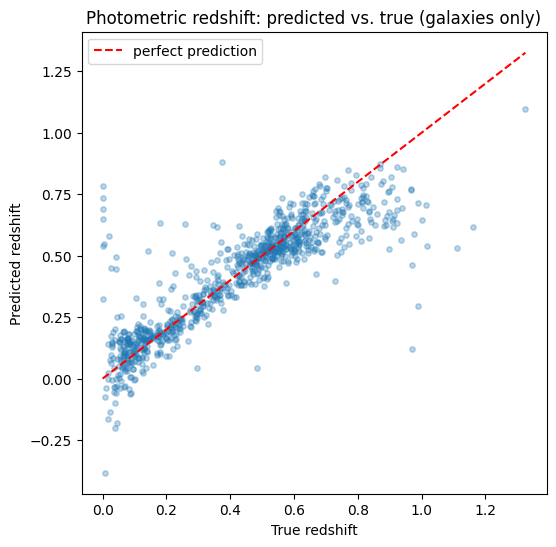

In [ ]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:.5f}")
print(f"RMSE: {rmse:.5f}")
print(f"MAE:  {mae:.5f}")
print(f"R^2:  {r2:.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, alpha=0.3, s=15)
lims = [0, max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, 'r--', label='perfect prediction')
ax.set_xlabel('True redshift'); ax.set_ylabel('Predicted redshift')
ax.set_title('Photometric redshift: predicted vs. true (galaxies only)')
ax.legend()
plt.show()


**🔧 Try it yourself:**
- Refit using **all three classes together** (remove the `sdss_sample['class'] == 'GALAXY'` filter) and recompute R². It should get noticeably worse — direct, real evidence that mixing physically distinct populations into one regression hurts performance, not just a theoretical warning.
- Add a clearly irrelevant feature (e.g. `sdss_sample['fiber_ID']`) into `X` and see whether R² improves, stays flat, or gets slightly worse on the test set — irrelevant features rarely help, and can sometimes hurt.
- Manually inject a few extreme outlier values into `y_test` (e.g. `y_test_outliers = y_test.copy(); y_test_outliers[:3] = 50`) and recompute MSE/RMSE/MAE on the corrupted array — watch how much more violently MSE/RMSE react than MAE.


## 6. Classification (Binary *and* Multi-Class)

### Binary classification: one special case, not "classification" in general
Let's start with the simplest possible version: is an object a quasar, or not? Logistic regression predicts a *probability* using the sigmoid function, which squashes any real number into the range (0, 1):
$$\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n$$

If $\sigma(z) > 0.5$ (the default threshold), we predict "quasar"; otherwise, "not quasar." The **decision boundary** is the set of points where $\sigma(z) = 0.5$ exactly — with two features, that boundary is a single line.

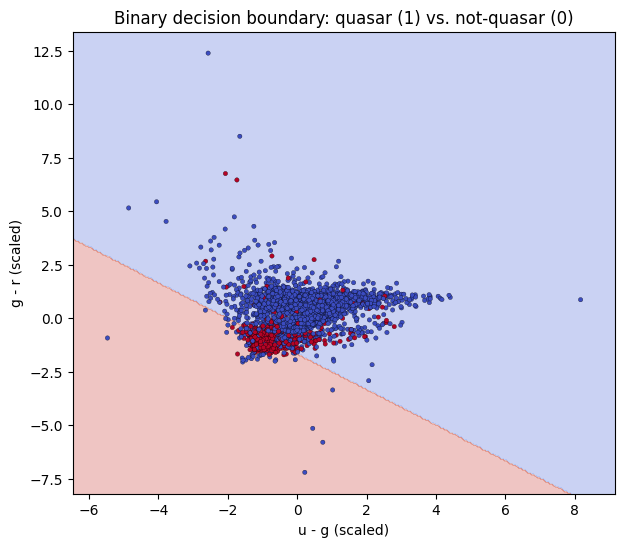

Test accuracy: 0.8973333333333333


In [ ]:
# Binary classification: quasar vs. not-quasar, using two color-index features for a 2D visualization
sdss_sample['u_minus_g'] = sdss_sample['u'] - sdss_sample['g']
sdss_sample['g_minus_r'] = sdss_sample['g'] - sdss_sample['r']

X2 = sdss_sample[['u_minus_g', 'g_minus_r']].values
y_binary = (sdss_sample['class'] == 'QSO').astype(int).values

X2_train, X2_test, yb_train, yb_test = train_test_split(
    X2, y_binary, test_size=0.3, random_state=42, stratify=y_binary
)
scaler2 = StandardScaler()
X2_train_s = scaler2.fit_transform(X2_train)
X2_test_s = scaler2.transform(X2_test)

logreg_binary = LogisticRegression()
logreg_binary.fit(X2_train_s, yb_train)

# Plot the decision boundary
xx, yy = np.meshgrid(np.linspace(X2_train_s[:, 0].min()-1, X2_train_s[:, 0].max()+1, 300),
                      np.linspace(X2_train_s[:, 1].min()-1, X2_train_s[:, 1].max()+1, 300))
Z = logreg_binary.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
ax.scatter(X2_train_s[:, 0], X2_train_s[:, 1], c=yb_train, cmap='coolwarm', s=10, edgecolor='k', linewidth=0.2)
ax.set_xlabel('u - g (scaled)'); ax.set_ylabel('g - r (scaled)')
ax.set_title('Binary decision boundary: quasar (1) vs. not-quasar (0)')
plt.show()

print("Test accuracy:", logreg_binary.score(X2_test_s, yb_test))


**🔧 Try it yourself:** Change the target to `(sdss_sample['class'] == 'STAR').astype(int)` and re-run — notice the decision boundary moves to a completely different location in color-space, since stars and quasars occupy different regions of this color diagram. This is the real astrophysical basis for color-based object selection used throughout survey astronomy.

### Multi-class classification: the general case
Most real classification problems in your subfields have **more than two categories**: star/galaxy/quasar (3 classes), stellar spectral type O through M (7 main classes), solar flare class A/B/C/M/X (5 classes), variable star type (many classes). Binary logistic regression extends to multiple classes via **softmax regression** (also called multinomial logistic regression), which produces a probability for *each* class simultaneously, using:
$$P(y = k \mid x) = \frac{e^{z_k}}{\sum_j e^{z_j}}$$
— a direct generalization of the sigmoid where the probabilities across all classes are forced to sum to 1. Instead of *one* decision boundary, you now get *multiple* boundaries carving feature space into as many regions as there are classes.

*(Note: in current versions of `scikit-learn`, `LogisticRegression` automatically uses this softmax/multinomial approach whenever it's given more than two classes — there's no separate setting you need to choose; the code below is identical in style to the binary case.)*


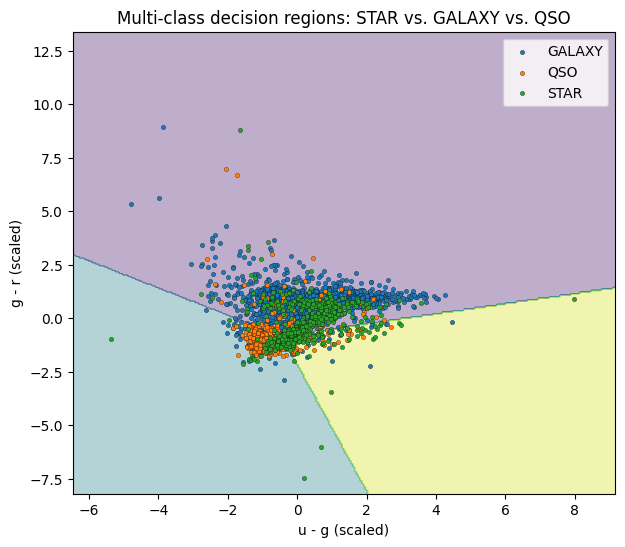

Test accuracy: 0.734


In [ ]:
# Multi-class classification: star vs. galaxy vs. quasar, same two features as above
# NOTE: deliberately using a fresh scaler and fresh variable names (Xm_*) here rather
# than reusing the binary section's X2_train_s/X2_test_s/scaler2 — keeping the binary
# and multi-class train/test splits completely separate avoids silently mixing up
# which rows go with which labels later in the notebook.
y_multi = sdss_sample['class'].values

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X2, y_multi, test_size=0.3, random_state=42, stratify=y_multi
)
scaler_m = StandardScaler()
Xm_train_s = scaler_m.fit_transform(Xm_train)
Xm_test_s = scaler_m.transform(Xm_test)

logreg_multi = LogisticRegression(max_iter=1000)
logreg_multi.fit(Xm_train_s, ym_train)

classes = logreg_multi.classes_
Z_multi = logreg_multi.predict(np.c_[xx.ravel(), yy.ravel()])
Z_multi_num = np.array([np.where(classes == c)[0][0] for c in Z_multi]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(xx, yy, Z_multi_num, alpha=0.35, cmap='viridis')
for i, c in enumerate(classes):
    mask = ym_train == c
    ax.scatter(Xm_train_s[mask, 0], Xm_train_s[mask, 1], s=10, label=c, edgecolor='k', linewidth=0.2)
ax.set_xlabel('u - g (scaled)'); ax.set_ylabel('g - r (scaled)')
ax.set_title('Multi-class decision regions: STAR vs. GALAXY vs. QSO')
ax.legend()
plt.show()

print("Test accuracy:", logreg_multi.score(Xm_test_s, ym_test))


Now you can see **three** distinct decision regions and **multiple** boundaries between them, all found automatically from the same softmax-regression idea — this is the direct fix for thinking of "classification" as always meaning one line splitting two groups.

### A brief but important distinction: multi-class vs. multi-label
**Multi-class** (what we just did) assumes each object belongs to *exactly one* of several categories. **Multi-label** classification allows an object to belong to *several categories at once* — e.g. a galaxy image tagged both "has spiral arms" and "shows AGN activity" simultaneously; a sunspot region flagged as both "delta-configuration" and "flare-productive." We won't implement multi-label classification this week, but it's worth naming now so you don't mistake it for multi-class later when you encounter it (it needs a different loss function and different evaluation metrics).

**Forward-pointer:** logistic regression needs the one-vs-rest/softmax machinery to handle multiple classes at all. Next week's tree-based methods (decision trees, random forests) and k-NN handle multi-class classification *natively*, with no special extension needed — one more reason those methods are often a convenient default for multi-class astronomy problems.

**🔧 Try it yourself:** Swap `X2 = sdss_sample[['u_minus_g', 'g_minus_r']].values` to use a different pair of features, e.g. `['g', 'r']` (raw magnitudes instead of colors) and re-run the multi-class cell — compare both the resulting accuracy and how visually clean the decision regions look. Colors often separate these classes better than raw magnitudes — see if your plot confirms that.



## 7. Classification Evaluation Metrics, Generalized

### The confusion matrix: binary, cell by cell
For our binary quasar/not-quasar model, every prediction falls into one of four cells:

| | Predicted: not-quasar | Predicted: quasar |
|---|---|---|
| **Actual: not-quasar** | True Negative (TN) | False Positive (FP) |
| **Actual: quasar** | False Negative (FN) | True Positive (TP) |

A **false positive** here means calling an ordinary star or galaxy a quasar — perhaps triggering unnecessary (and expensive) spectroscopic follow-up. A **false negative** means missing a real quasar — perhaps losing a scientifically valuable object from your sample entirely. Which mistake is worse depends entirely on your science goal, which is exactly why we don't just report accuracy and call it done.


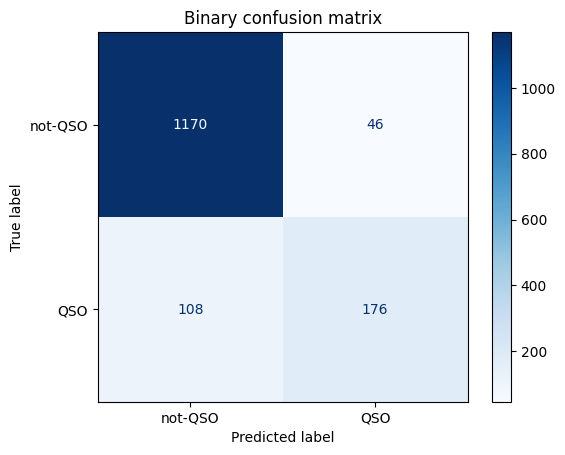

In [11]:

yb_pred = logreg_binary.predict(X2_test_s)
cm_binary = confusion_matrix(yb_test, yb_pred)
disp = ConfusionMatrixDisplay(cm_binary, display_labels=['not-QSO', 'QSO'])
disp.plot(cmap='Blues')
plt.title('Binary confusion matrix')
plt.show()



### Generalizing to N classes
The same idea extends directly to our 3-class star/galaxy/quasar problem — the matrix just grows to 3×3 (in general, N×N for N classes), with the correct predictions running down the diagonal and every off-diagonal cell representing a specific kind of confusion (e.g. "true galaxy predicted as quasar").


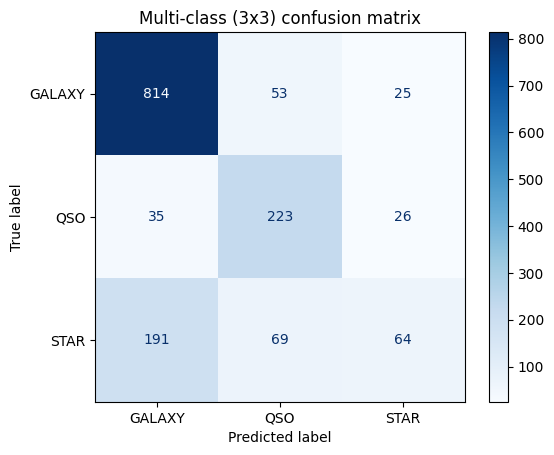

              precision    recall  f1-score   support

      GALAXY       0.78      0.91      0.84       892
         QSO       0.65      0.79      0.71       284
        STAR       0.56      0.20      0.29       324

    accuracy                           0.73      1500
   macro avg       0.66      0.63      0.61      1500
weighted avg       0.71      0.73      0.70      1500



In [ ]:
ym_pred = logreg_multi.predict(Xm_test_s)
cm_multi = confusion_matrix(ym_test, ym_pred, labels=classes)
disp_multi = ConfusionMatrixDisplay(cm_multi, display_labels=classes)
disp_multi.plot(cmap='Blues')
plt.title('Multi-class (3x3) confusion matrix')
plt.show()

print(classification_report(ym_test, ym_pred))


### Reading the classification report
For each class you get **precision** (of everything the model called this class, what fraction actually was?), **recall** (of everything that actually is this class, what fraction did the model catch?), and **F1** (their harmonic mean, balancing both). With more than two classes, you also need to decide how to average these across classes:
- **Macro average**: treat every class equally, regardless of how many examples it has — useful when a rare class matters just as much scientifically as a common one.
- **Weighted average**: weight each class's contribution by how many examples it has — useful when you care about overall performance across your actual dataset as it's distributed.

### Real class imbalance, right here in this dataset
Check the class counts in `sdss_sample['class'].value_counts()` from Section 2 — galaxies substantially outnumber quasars and stars in this real survey data (this is real, not manufactured for the exercise: galaxies genuinely dominate flux-limited optical surveys). This is exactly the scenario where **accuracy alone can be misleading**: a model that just always predicted "GALAXY" would already get a majority of predictions right by accident, while being scientifically useless for finding quasars.

**🔧 Try it yourself:** Compute what accuracy a "predict GALAXY always" model would get, using `(ym_test == 'GALAXY').mean()`. Compare that number to the *recall* for the QSO class specifically in the printed classification report above — a wide gap between "high overall accuracy" and "low recall on the class you actually care about" is the single most common way naive model evaluation misleads people in imbalanced astronomy datasets.

### ROC curves (binary tools, with a note for multi-class)
The ROC curve plots the true positive rate against the false positive rate as you slide the classification threshold away from the default 0.5, letting you see the full range of possible tradeoffs rather than a single operating point. ROC/AUC is naturally a binary-classification tool; for multi-class problems, it needs a one-vs-rest extension (computing a separate ROC curve for each class against all the others) — worth knowing exists, though we won't build it here.


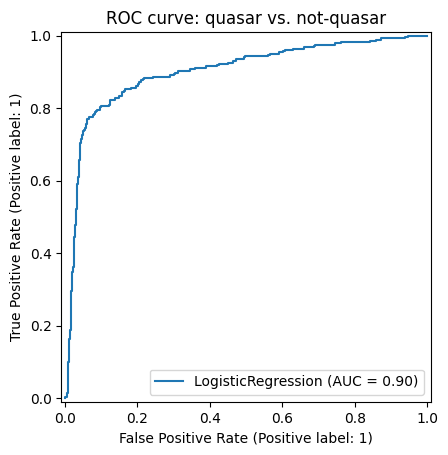

AUC: 0.9003862815048184


In [ ]:
RocCurveDisplay.from_estimator(logreg_binary, X2_test_s, yb_test)
plt.title('ROC curve: quasar vs. not-quasar')
plt.show()

print("AUC:", roc_auc_score(yb_test, logreg_binary.predict_proba(X2_test_s)[:, 1]))


## 8. Cross-Validation

### Why one train/test split isn't always enough
A single train/test split gives you one number — but that number depends on exactly *which* points happened to land in the test set. With a modest sample size (common when working with a rare class of astronomical object), that single split could paint an overly optimistic or overly pessimistic picture purely by chance.

**k-fold cross-validation** fixes this: split the data into $k$ equal chunks ("folds"), train on $k-1$ of them and validate on the remaining one, then rotate which fold is held out and repeat $k$ times. You end up with $k$ performance scores instead of one, and can report both their mean (best estimate of true performance) and their spread (how much that estimate might vary).

### What the code below will do
We'll run 5-fold cross-validation on both a regression model (redshift prediction) and a classification model (3-class prediction), and compare that to the variability you'd get from just a handful of *different* single train/test splits.


In [ ]:
# Cross-validation on the regression task
X_reg = scaler.fit_transform(galaxies[['u', 'g', 'r', 'i', 'z']].values)
y_reg = galaxies['redshift'].values

cv_scores_reg = cross_val_score(LinearRegression(), X_reg, y_reg, cv=5, scoring='r2')
print("Regression R^2 across 5 folds:", np.round(cv_scores_reg, 3))
print(f"Mean R^2: {cv_scores_reg.mean():.3f}  (+/- {cv_scores_reg.std():.3f})")

# Cross-validation on the classification task (fresh scaler fit on the full feature set,
# since cross_val_score handles the train/validation splitting internally)
X_clf = StandardScaler().fit_transform(X2)
y_clf = y_multi
cv_scores_clf = cross_val_score(LogisticRegression(max_iter=1000), X_clf, y_clf, cv=5)
print("\nClassification accuracy across 5 folds:", np.round(cv_scores_clf, 3))
print(f"Mean accuracy: {cv_scores_clf.mean():.3f}  (+/- {cv_scores_clf.std():.3f})")

Regression R^2 across 5 folds: [0.748 0.698 0.713 0.703 0.691]
Mean R^2: 0.711  (+/- 0.020)

Classification accuracy across 5 folds: [0.734 0.725 0.74  0.73  0.736]
Mean accuracy: 0.733  (+/- 0.005)



**🔧 Try it yourself:** Rebuild `sdss_sample` from Section 2 with `n=300` instead of `n=5000` (a much smaller sample — closer to what you might have for a genuinely rare class of astronomical object), then re-run this cell. Watch the standard deviation across folds grow noticeably — smaller datasets give a less stable, less trustworthy performance estimate, exactly the situation cross-validation is designed to help you detect rather than hide.



## 9. Overfitting / Underfitting, Revisited

Notebook 0 §8 showed underfitting and overfitting with polynomial curve-fitting. The same phenomenon shows up in classification and regression models used here, controlled by a **complexity knob** — for k-Nearest Neighbors, that knob is $k$, the number of neighbors consulted:

- **Small $k$** (e.g. $k=1$): the model follows every quirk of the training data extremely closely — high variance, prone to overfitting noisy individual points.
- **Large $k$**: the model averages over so many neighbors that it can miss real structure — high bias, prone to underfitting.

### What the code below will do
We'll sweep $k$ across a range for a k-NN classifier on the 3-class problem, plotting training accuracy against validation accuracy at each value — this is called a **validation curve**, and the gap between the two curves is a direct, visual readout of overfitting.


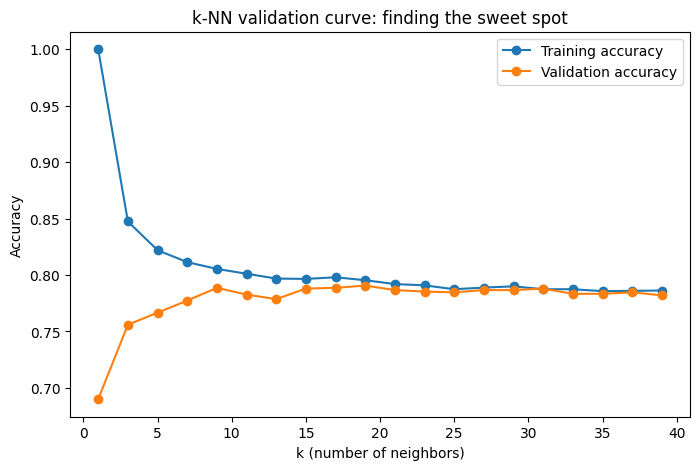

Best k by validation accuracy: 19


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X_clf, y_clf, test_size=0.3, random_state=42, stratify=y_clf)

k_values = range(1, 41, 2)
train_acc, val_acc = [], []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    train_acc.append(knn.score(X_train, y_train))
    val_acc.append(knn.score(X_val, y_val))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, train_acc, marker='o', label='Training accuracy')
ax.plot(k_values, val_acc, marker='o', label='Validation accuracy')
ax.set_xlabel('k (number of neighbors)'); ax.set_ylabel('Accuracy')
ax.set_title('k-NN validation curve: finding the sweet spot')
ax.legend()
plt.show()

best_k = k_values[np.argmax(val_acc)]
print(f"Best k by validation accuracy: {best_k}")


**🔧 Try it yourself:** Look at the left edge of the plot ($k=1$) — training accuracy should be at or near its maximum there (the model can nearly memorize the training set), while validation accuracy is comparatively worse — that gap *is* overfitting, visually. Now extend `k_values` up to `range(1, 200, 5)` and re-run — both curves should eventually decline together as $k$ becomes so large the model oversimplifies (underfitting). Try shrinking `sdss_sample` to `n=500` and re-running the whole section — with less data, overfitting at small $k$ typically becomes even more pronounced.



## 10. Self-Check Questions

Before Session 1, make sure you can answer these in your own words:

1. Give one example each of a supervised, an unsupervised, and a semi-supervised problem from *your own* subfield (not one already used in this notebook).
2. Why is it a problem to evaluate a model on the same data it was trained on?
3. Give an example of a real astronomy problem that could reasonably be framed as *either* regression or classification, and explain the tradeoff.
4. Why did mixing stars, galaxies, and quasars together hurt the redshift regression in Section 5?
5. What does a false positive mean, concretely, in the quasar-classification example — and why might a false negative be worse (or better) depending on the science goal?
6. Why can't you just reuse a 2×2 confusion matrix for a 3-class problem — what has to change?
7. What's the difference between macro-averaged and weighted-averaged F1, and when would you prefer one over the other?
8. Why does a single train/test split sometimes give a misleading picture of model performance, and how does cross-validation address that?
9. In the k-NN validation curve, what visual signature tells you the model is overfitting versus underfitting?

You're ready for Session 1 once you can answer all nine without looking back at the notebook.
